In [20]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


In [3]:
import pandas as pd  # For data manipulation
import numpy as np  # For numerical operations
from sklearn.model_selection import train_test_split # For splitting data
from sklearn.ensemble import RandomForestRegressor # Example model
from sklearn.metrics import mean_squared_error, r2_score # For evaluation
import matplotlib.pyplot as plt # For visualization (optional)
from scipy import stats
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
import pandas as pd


2025-07-07 06:55:53.468832: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751896553.556706 3420779 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751896553.580234 3420779 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1751896553.783525 3420779 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751896553.783550 3420779 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751896553.783552 3420779 computation_placer.cc:177] computation placer alr

Original DataFrame shape: (260, 8)
DataFrame shape after outlier removal: (236, 8)


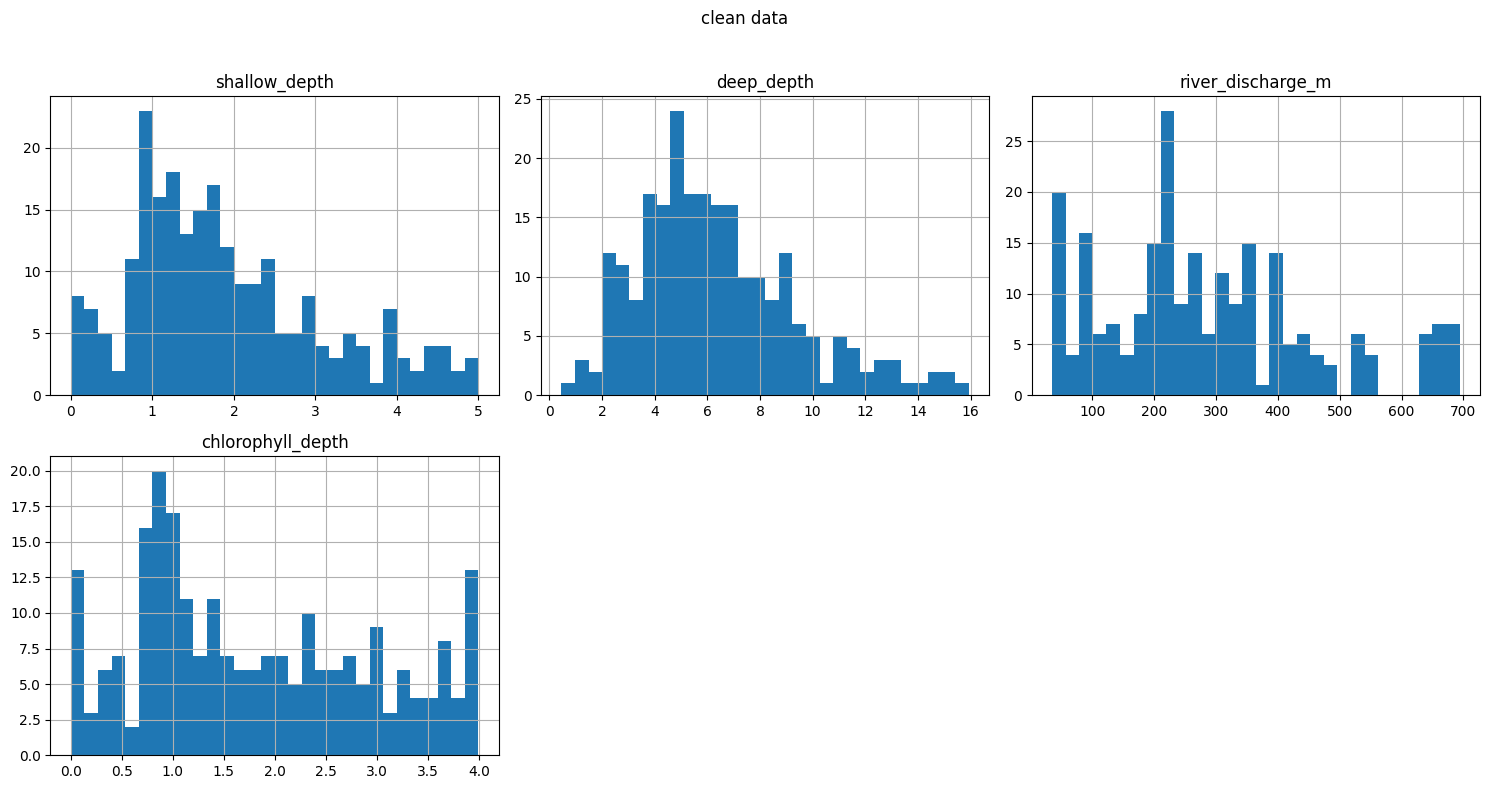

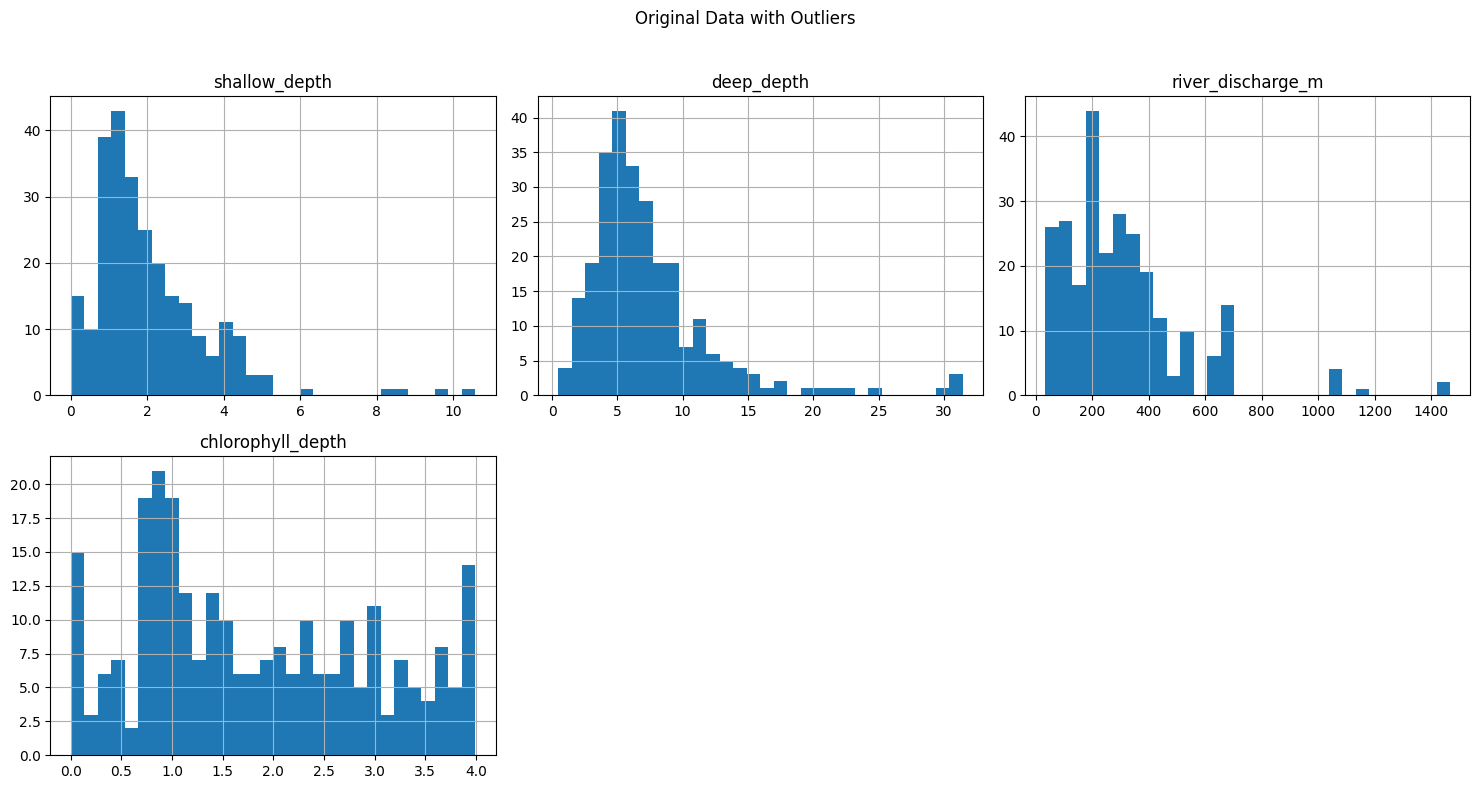

In [10]:
# 2. Load and Prepare Your Data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

import pandas as pd
from scipy import stats

feature_cols = ['shallow_depth', 'deep_depth','river_discharge_m']
target_col = 'chlorophyll_depth'

# Remove all rows where 'chlorophyll_depth' > 6
data = data[data['chlorophyll_depth'] <= 4].reset_index(drop=True)
def remove_outliers(df):
    """
    Removes rows containing outliers in 'shallow_depth', 'deep_depth', and
    'chlorophyll_depth' columns using the Z-score method.

    Args:
        df (pd.DataFrame): The input DataFrame with the specified columns.

    Returns:
        pd.DataFrame: A new DataFrame with outliers removed.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]  # Include all feature columns and target column

    for col in cols_to_check:
        if col in df_cleaned.columns:
            z = stats.zscore(df_cleaned[col])
            outlier_mask = abs(z) > 2  # You can adjust the Z-score threshold (e.g., to 2.5)
            df_cleaned = df_cleaned[~outlier_mask]
        else:
            print(f"Warning: Column '{col}' not found in the DataFrame.")
    return df_cleaned

# Assuming your DataFrame is named 'data'
# Load your data first if you haven't already
# data = pd.read_csv('your_data_file.csv', encoding='latin-1') # Make sure to use the correct encoding

# Apply the outlier removal function
if 'data' in locals():
    data_cleaned = remove_outliers(data)
    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after outlier removal:", data_cleaned.shape)
    # Now you can use 'data_cleaned' for further analysis and model building
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


import matplotlib.pyplot as plt
def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    # Combine feature columns and target column for plotting
    columns_to_plot = feature_cols + [target_col]

    # Plot a histogram for each column
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/6 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - loss: 2.1719

2025-07-07 07:08:57.982481: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_404', 32 bytes spill stores, 32 bytes spill loads

2025-07-07 07:08:58.100944: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_404', 32 bytes spill stores, 32 bytes spill loads



6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - loss: 1.9502 - val_loss: 1.5465
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.6007 - val_loss: 1.1593
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4056 - val_loss: 1.1885
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.4082 - val_loss: 1.2701
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3550 - val_loss: 1.1643
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3728 - val_loss: 1.1760
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2807 - val_loss: 1.2052
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3822 - val_loss: 1.1633
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2568 - val_loss: 1.1872
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2285 - val_loss: 1.1849
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2341 - val_loss: 1.1711
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1688 - val_loss: 1.1790
Epoch 13/50
6/

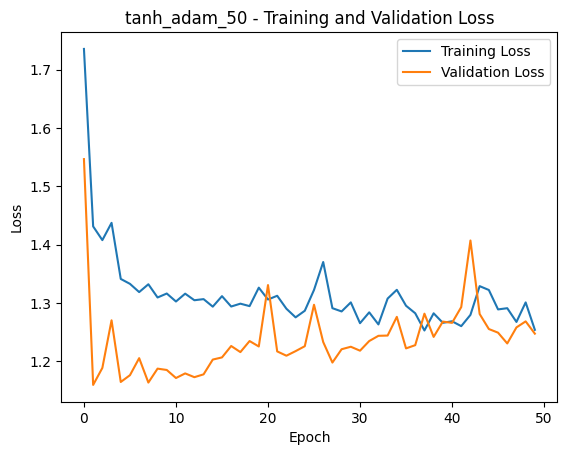

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 394ms/step - loss: 3.1500 - val_loss: 1.2589
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3931 - val_loss: 1.2573
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.1779 - val_loss: 1.1731
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3636 - val_loss: 1.1645
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3805 - val_loss: 1.2042
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3811 - val_loss: 1.1758
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2749 - val_loss: 1.1731
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2083 - val_loss: 1.1743
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4047 - val_loss: 1.1736
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2613 - val_loss: 1.2162
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3200 - val_loss: 1.1843
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2449 - val_loss: 1.1725


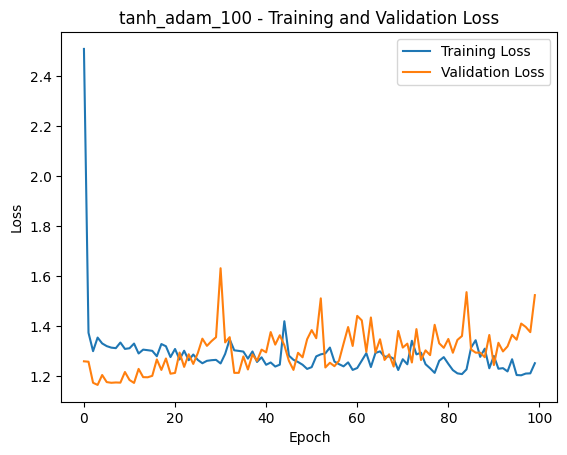

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 393ms/step - loss: 1.8028 - val_loss: 1.3225
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4893 - val_loss: 1.1787
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3540 - val_loss: 1.1778
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3672 - val_loss: 1.1760
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3786 - val_loss: 1.1691
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3551 - val_loss: 1.2002
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2616 - val_loss: 1.1652
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2878 - val_loss: 1.1782
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3107 - val_loss: 1.2069
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3256 - val_loss: 1.1827
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3012 - val_loss: 1.1946
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2934 - val_loss: 1.2398


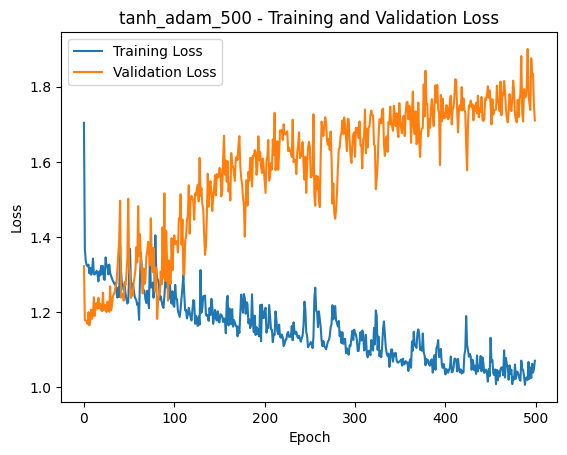

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/6 ━━━━━━━━━━━━━━━━━━━━ 4s 939ms/step - loss: 5.5471

2025-07-07 07:10:19.824890: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_244', 24 bytes spill stores, 24 bytes spill loads

2025-07-07 07:10:19.917500: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_244', 8 bytes spill stores, 8 bytes spill loads

2025-07-07 07:10:19.953916: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_244', 24 bytes spill stores, 24 bytes spill loads



6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 722ms/step - loss: 4.2202 - val_loss: 1.1720
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2807 - val_loss: 1.1853
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3952 - val_loss: 1.4262
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4366 - val_loss: 1.3777
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3279 - val_loss: 1.3948
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4820 - val_loss: 1.1736
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3456 - val_loss: 1.2620
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3960 - val_loss: 1.4556
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4713 - val_loss: 1.1659
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3362 - val_loss: 1.2487
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3457 - val_loss: 1.2130
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3227 - val_loss: 1.1827
Epoch 13/50

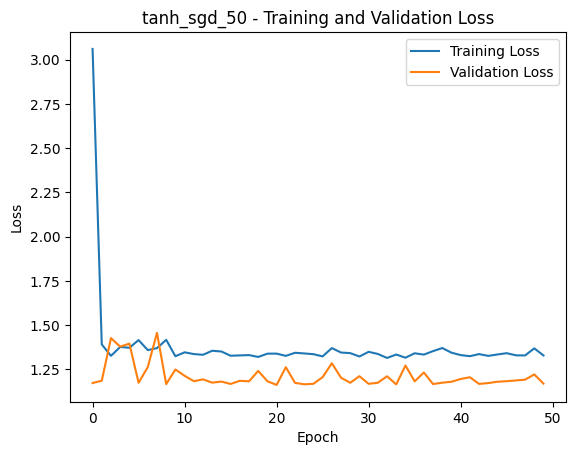

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 370ms/step - loss: 3.9663 - val_loss: 1.2213
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4613 - val_loss: 1.2438
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3556 - val_loss: 1.1949
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4255 - val_loss: 1.2219
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3307 - val_loss: 1.1858
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4776 - val_loss: 1.1927
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3572 - val_loss: 1.5021
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3209 - val_loss: 1.1701
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3743 - val_loss: 1.1666
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2998 - val_loss: 1.1674
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3589 - val_loss: 1.4168
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3854 - val_loss: 1.2495


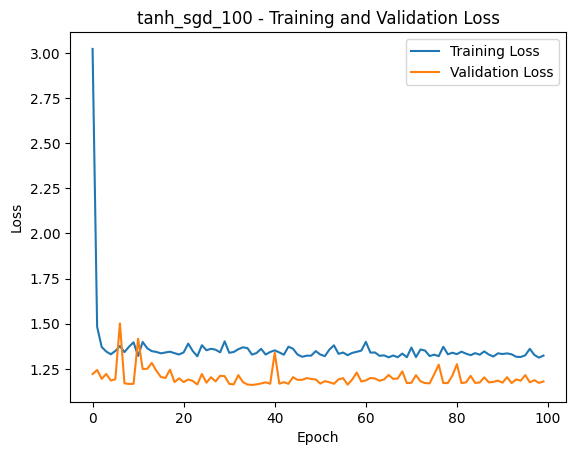

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 369ms/step - loss: 2.4202 - val_loss: 1.1826
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3434 - val_loss: 1.3634
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3076 - val_loss: 1.2979
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4109 - val_loss: 1.2188
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3076 - val_loss: 1.1728
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3147 - val_loss: 1.2245
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2859 - val_loss: 1.1775
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3187 - val_loss: 1.1629
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3997 - val_loss: 1.2344
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2833 - val_loss: 1.1688
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3675 - val_loss: 1.1838
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4800 - val_loss: 1.2691


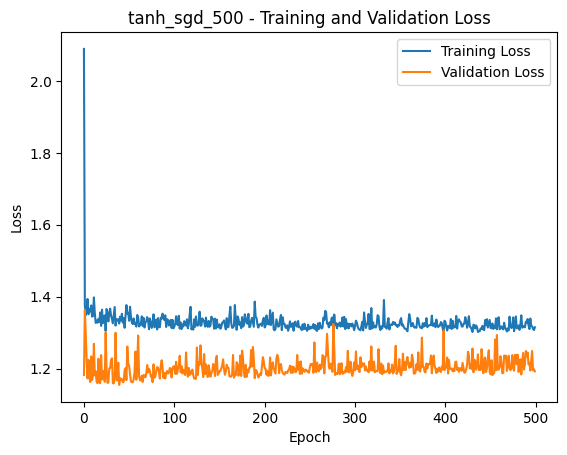

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 380ms/step - loss: 4.0265 - val_loss: 1.1626
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3487 - val_loss: 1.3263
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3536 - val_loss: 1.2610
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4358 - val_loss: 1.5847
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.5151 - val_loss: 1.2128
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2361 - val_loss: 1.1655
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3604 - val_loss: 1.1568
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3633 - val_loss: 1.4256
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4276 - val_loss: 1.2189
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4451 - val_loss: 1.2033
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3272 - val_loss: 1.1672
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3533 - val_loss: 1.2149
Epoch 13/50

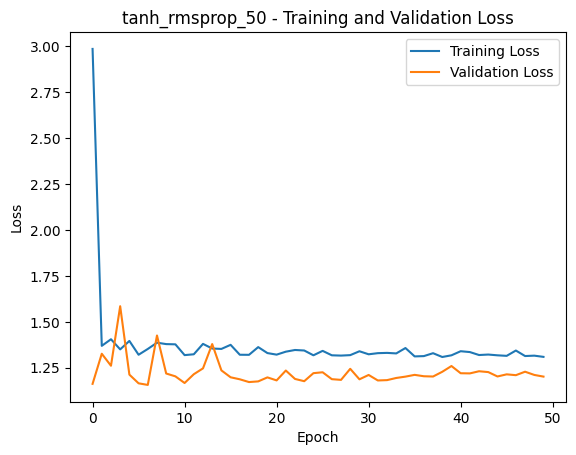

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 378ms/step - loss: 3.8448 - val_loss: 1.1883
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2647 - val_loss: 1.1753
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3390 - val_loss: 1.1846
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4722 - val_loss: 1.2308
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3230 - val_loss: 1.1659
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3157 - val_loss: 1.3064
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3018 - val_loss: 1.3539
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3178 - val_loss: 1.2237
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3032 - val_loss: 1.2624
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3936 - val_loss: 1.2545
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3002 - val_loss: 1.2305
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2346 - val_loss: 1.2254


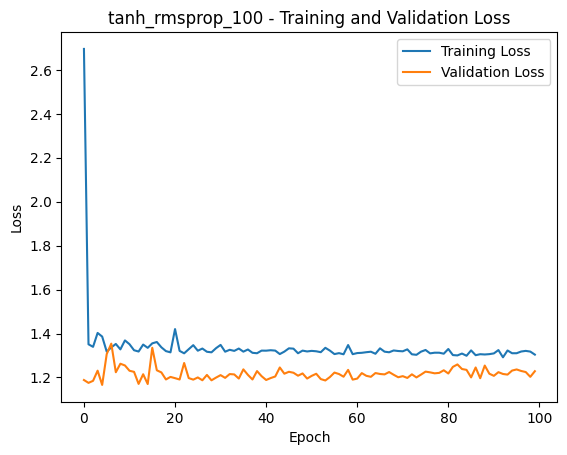

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 378ms/step - loss: 2.8217 - val_loss: 1.2505
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3977 - val_loss: 1.1711
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3227 - val_loss: 1.1673
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3959 - val_loss: 1.2605
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3683 - val_loss: 1.2033
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3379 - val_loss: 1.7872
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.5083 - val_loss: 1.1890
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3827 - val_loss: 1.1745
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2330 - val_loss: 1.2256
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3556 - val_loss: 1.2498
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4714 - val_loss: 1.1700
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2655 - val_loss: 1.1674


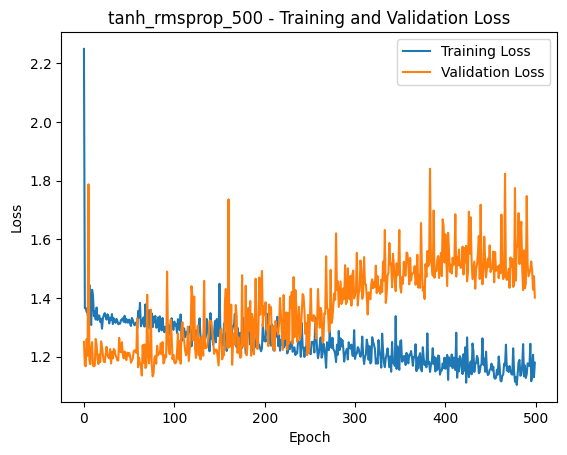

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/6 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - loss: 3.1405

2025-07-07 07:12:53.396856: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_404', 32 bytes spill stores, 32 bytes spill loads

2025-07-07 07:12:54.067686: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_404', 32 bytes spill stores, 32 bytes spill loads



6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - loss: 2.7074 - val_loss: 1.8959
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.8794 - val_loss: 1.2774
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3017 - val_loss: 1.1724
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3616 - val_loss: 1.1826
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4052 - val_loss: 1.1805
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3688 - val_loss: 1.1724
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3323 - val_loss: 1.1856
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3691 - val_loss: 1.1990
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3563 - val_loss: 1.2029
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3487 - val_loss: 1.1928
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3206 - val_loss: 1.1852
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3986 - val_loss: 1.1832
Epoch 13/50
6/

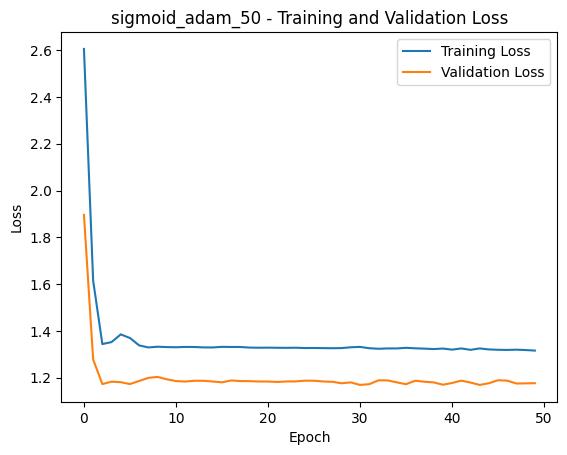

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 384ms/step - loss: 5.3548 - val_loss: 3.3695
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.6615 - val_loss: 1.8314
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.7804 - val_loss: 1.2601
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3551 - val_loss: 1.1716
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3877 - val_loss: 1.1911
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4380 - val_loss: 1.1870
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4159 - val_loss: 1.1731
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3783 - val_loss: 1.1742
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2701 - val_loss: 1.1889
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4051 - val_loss: 1.2040
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3754 - val_loss: 1.2123
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3705 - val_loss: 1.1978


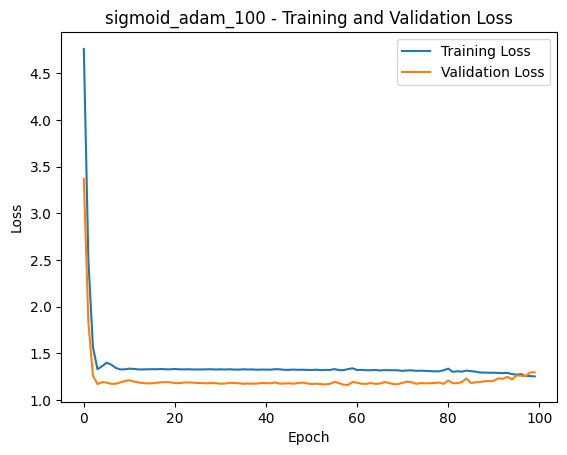

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 385ms/step - loss: 4.0982 - val_loss: 2.8470
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.2812 - val_loss: 1.6548
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.5712 - val_loss: 1.2581
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3309 - val_loss: 1.1750
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2924 - val_loss: 1.1750
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2954 - val_loss: 1.1754
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2755 - val_loss: 1.1720
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3565 - val_loss: 1.1749
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3606 - val_loss: 1.1819
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3358 - val_loss: 1.1894
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4429 - val_loss: 1.1963
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3427 - val_loss: 1.1963


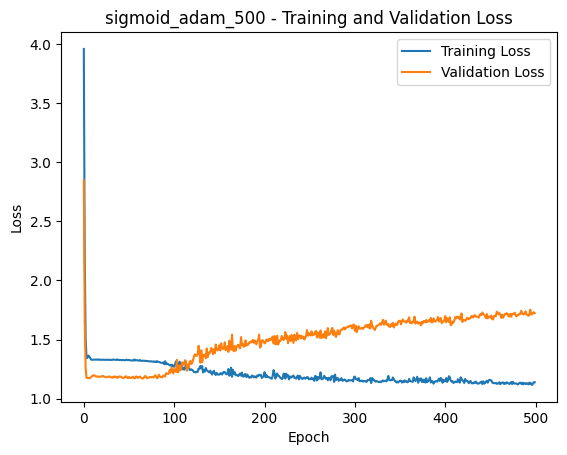

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/6 ━━━━━━━━━━━━━━━━━━━━ 4s 930ms/step - loss: 4.5168

2025-07-07 07:14:15.417482: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_244', 24 bytes spill stores, 24 bytes spill loads

2025-07-07 07:14:15.497292: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_244', 8 bytes spill stores, 8 bytes spill loads

2025-07-07 07:14:15.709678: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_244', 24 bytes spill stores, 24 bytes spill loads



6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 667ms/step - loss: 2.7576 - val_loss: 1.3144
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3285 - val_loss: 1.1825
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3528 - val_loss: 1.1803
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3293 - val_loss: 1.1846
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3344 - val_loss: 1.2120
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3493 - val_loss: 1.1866
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2781 - val_loss: 1.1751
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3110 - val_loss: 1.1828
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4054 - val_loss: 1.1781
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3461 - val_loss: 1.2066
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2784 - val_loss: 1.2094
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2623 - val_loss: 1.1811
Epoch 13/50

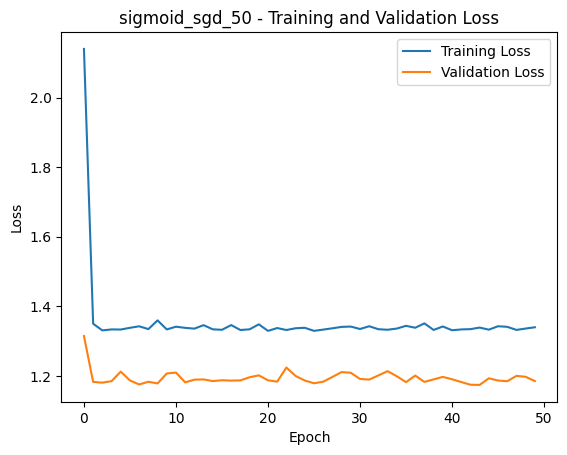

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 365ms/step - loss: 5.8703 - val_loss: 1.6230
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4272 - val_loss: 1.2040
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2003 - val_loss: 1.1807
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3358 - val_loss: 1.1949
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3044 - val_loss: 1.1832
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2675 - val_loss: 1.1984
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3658 - val_loss: 1.2000
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2560 - val_loss: 1.1749
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2870 - val_loss: 1.1810
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2948 - val_loss: 1.2049
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.5315 - val_loss: 1.2228
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3923 - val_loss: 1.2025


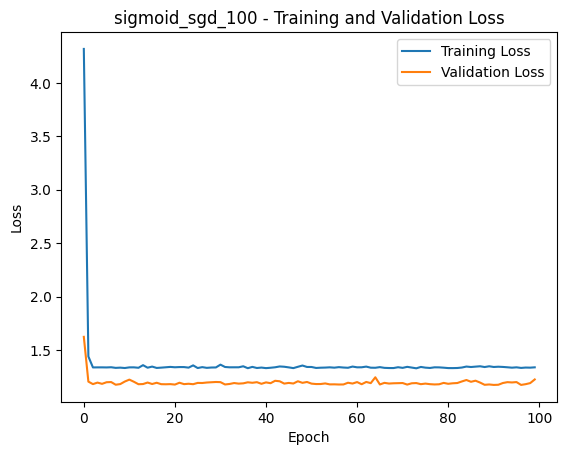

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 361ms/step - loss: 2.9539 - val_loss: 1.4764
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4588 - val_loss: 1.2367
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3379 - val_loss: 1.1973
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3107 - val_loss: 1.1760
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3686 - val_loss: 1.1907
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1932 - val_loss: 1.1857
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2865 - val_loss: 1.1955
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3548 - val_loss: 1.2000
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3747 - val_loss: 1.1797
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3507 - val_loss: 1.1992
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3488 - val_loss: 1.1871
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3755 - val_loss: 1.1923


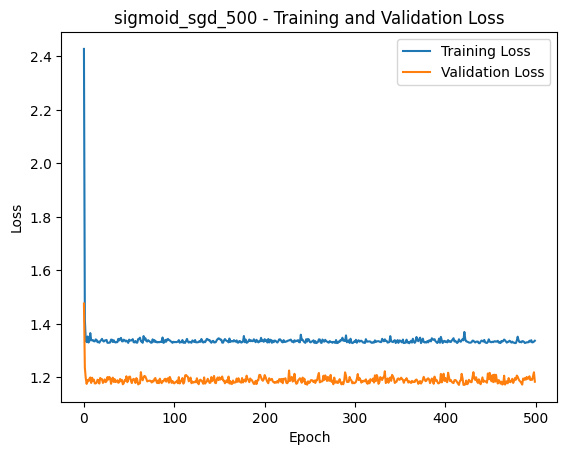

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 375ms/step - loss: 2.9098 - val_loss: 1.5678
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4818 - val_loss: 1.2647
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2885 - val_loss: 1.1852
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3250 - val_loss: 1.1853
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2925 - val_loss: 1.1830
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4429 - val_loss: 1.2246
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3119 - val_loss: 1.1819
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3988 - val_loss: 1.2018
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3663 - val_loss: 1.1916
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3847 - val_loss: 1.2496
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3428 - val_loss: 1.1937
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3771 - val_loss: 1.2101
Epoch 13/50

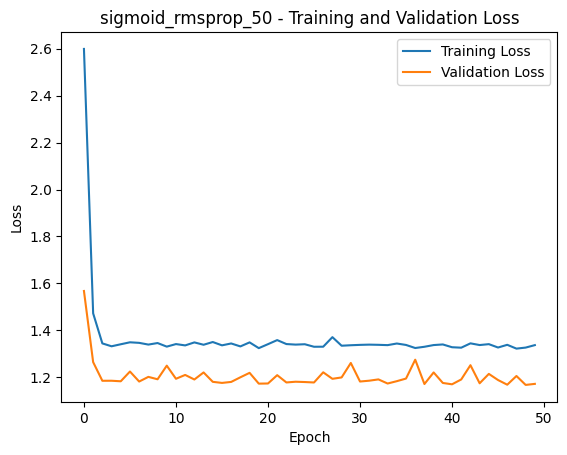

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 372ms/step - loss: 3.9256 - val_loss: 1.8075
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.8671 - val_loss: 1.3455
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3820 - val_loss: 1.2342
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3198 - val_loss: 1.1791
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3858 - val_loss: 1.1851
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3239 - val_loss: 1.1737
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4505 - val_loss: 1.1933
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1101 - val_loss: 1.1733
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3238 - val_loss: 1.1752
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2914 - val_loss: 1.1815
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3464 - val_loss: 1.1871
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3499 - val_loss: 1.1815


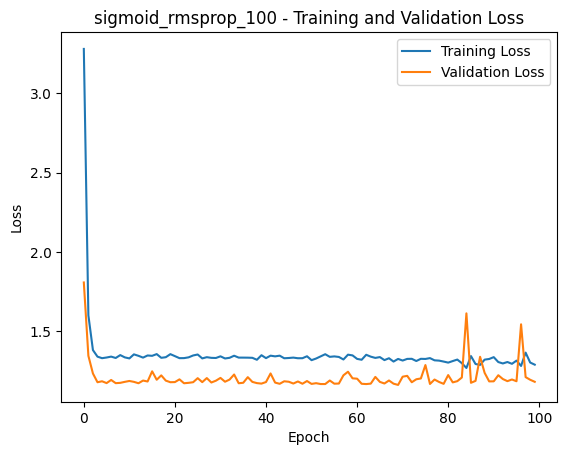

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 379ms/step - loss: 6.2995 - val_loss: 3.1125
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.7148 - val_loss: 1.9828
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.8787 - val_loss: 1.5340
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.4516 - val_loss: 1.3270
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3883 - val_loss: 1.2423
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3364 - val_loss: 1.1982
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3515 - val_loss: 1.1890
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2977 - val_loss: 1.1840
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2741 - val_loss: 1.2090
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3933 - val_loss: 1.2161
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4074 - val_loss: 1.2010
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4025 - val_loss: 1.1919


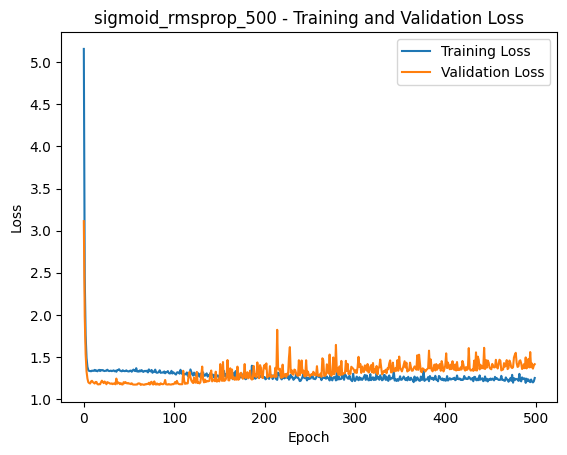

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Assuming you have run the data splitting code and have train_df, val_df, test_df
train_df, temp_df = train_test_split(data, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]




# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [50, 100, 500]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            model = Sequential([
                Dense(256, activation=activation, input_shape=(x_train.shape[1],)),  # Input layer
                Dense(128, activation=activation),  # Hidden layer
                Dense(64, activation=activation),  # Hidden layer
                Dense(32, activation=activation),  # Hidden layer
                Dense(1)  # Output layer (regression)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            # Store the model and its performance
            # You can use a dictionary or a list to store the models and their performance
            # For example:
            # models[activation + '_' + optimizer + '_' + str(epoch)] = (model, mse)
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [12]:
# Sort models by MSE (lowest to highest)
sorted_models = sorted(models.items(), key=lambda item: item[1][1] if not np.isnan(item[1][1]) else float('inf'))
print("Models sorted by Test MSE (lowest to highest):")
for name, (mdl, mse_val) in sorted_models:
  print(f"{name}: Test MSE = {mse_val}")

Models sorted by Test MSE (lowest to highest):
sigmoid_rmsprop_500: Test MSE = 1.4771783351898193
tanh_adam_50: Test MSE = 1.4824072122573853
sigmoid_rmsprop_100: Test MSE = 1.4881649017333984
sigmoid_adam_100: Test MSE = 1.4917747974395752
tanh_sgd_100: Test MSE = 1.4943839311599731
tanh_rmsprop_500: Test MSE = 1.494495153427124
tanh_rmsprop_50: Test MSE = 1.4951523542404175
tanh_sgd_500: Test MSE = 1.4988200664520264
tanh_sgd_50: Test MSE = 1.4992260932922363
sigmoid_rmsprop_50: Test MSE = 1.5061732530593872
tanh_rmsprop_100: Test MSE = 1.5078997611999512
sigmoid_adam_50: Test MSE = 1.5091972351074219
sigmoid_sgd_500: Test MSE = 1.5231431722640991
sigmoid_sgd_50: Test MSE = 1.5241341590881348
sigmoid_sgd_100: Test MSE = 1.5570136308670044
tanh_adam_100: Test MSE = 1.5947320461273193
sigmoid_adam_500: Test MSE = 1.6339490413665771
tanh_adam_500: Test MSE = 1.697755217552185


Model: tanh_adam_25, Test MSE: 1.9075324535369873
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


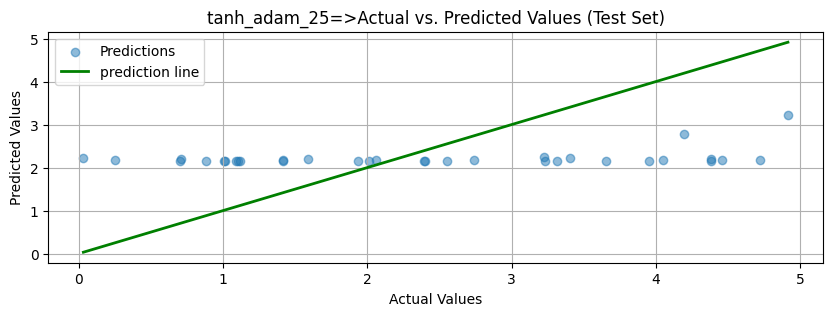

Model: tanh_adam_50, Test MSE: 1.807669997215271
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7519645604c0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


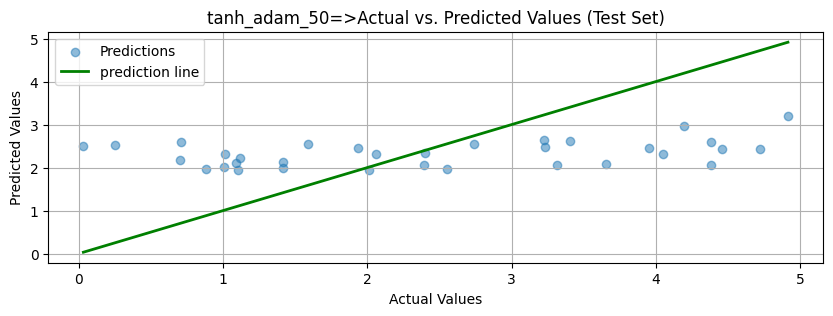

Model: tanh_adam_100, Test MSE: 1.8379379510879517
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 252ms/step


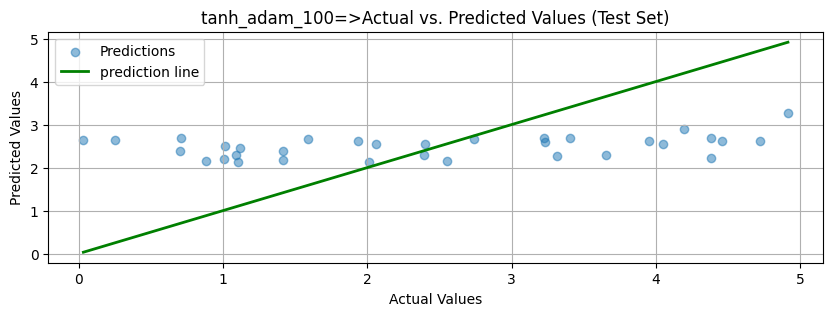

Model: tanh_adam_500, Test MSE: 1.7752279043197632
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 246ms/step


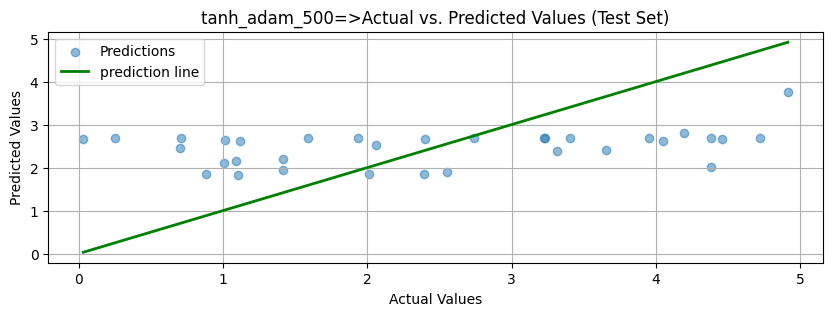

Model: tanh_sgd_25, Test MSE: 2.0236799716949463
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step


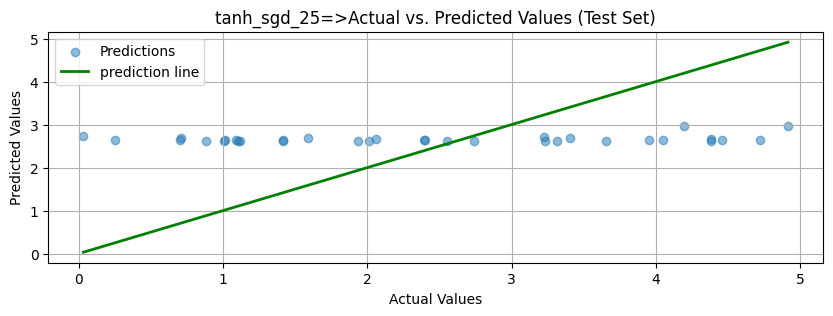

Model: tanh_sgd_50, Test MSE: 2.0155322551727295
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


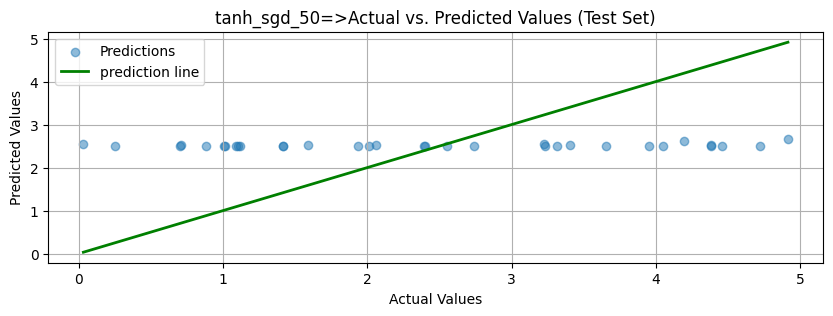

Model: tanh_sgd_100, Test MSE: 2.011216402053833
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step


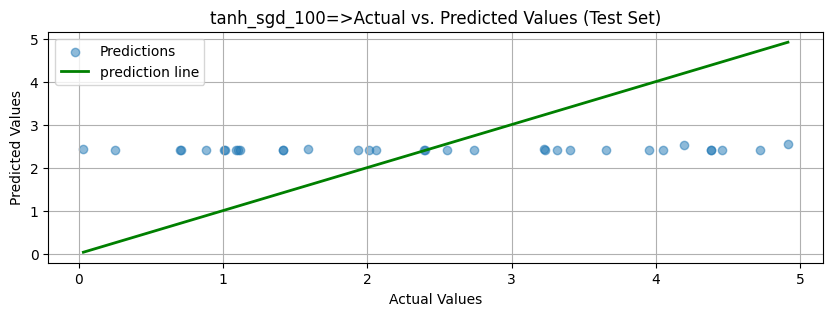

Model: tanh_sgd_500, Test MSE: 2.0599358081817627
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


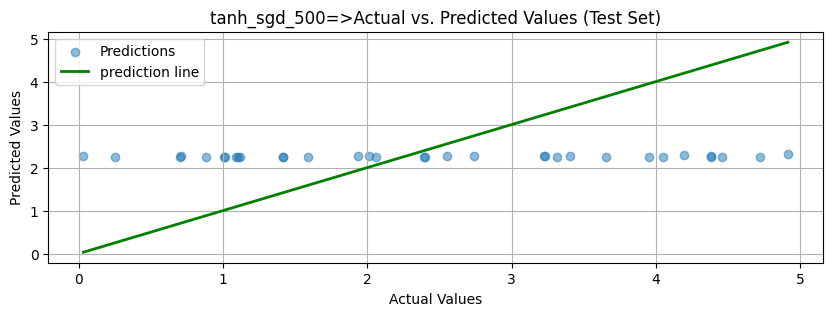

Model: tanh_rmsprop_25, Test MSE: 1.8675950765609741
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 239ms/step


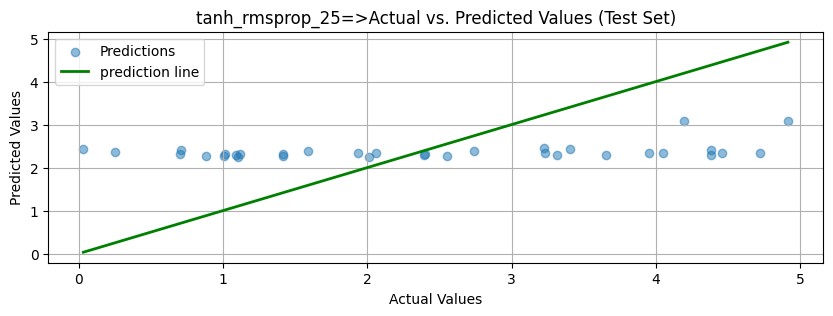

Model: tanh_rmsprop_50, Test MSE: 2.098276138305664
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 250ms/step


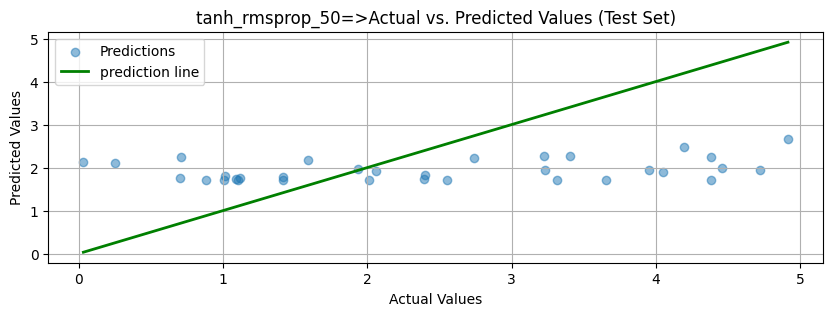

Model: tanh_rmsprop_100, Test MSE: 1.844407558441162
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step


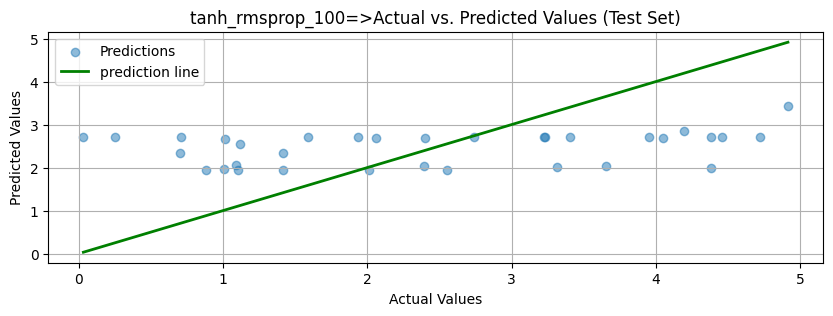

Model: tanh_rmsprop_500, Test MSE: 1.8631747961044312
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 254ms/step


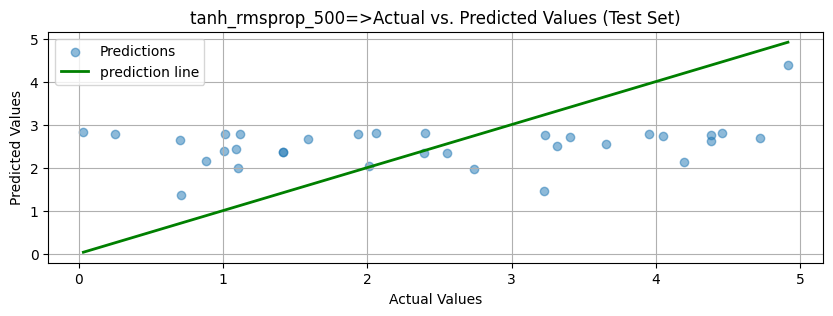

Model: sigmoid_adam_25, Test MSE: 1.9106906652450562
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 244ms/step


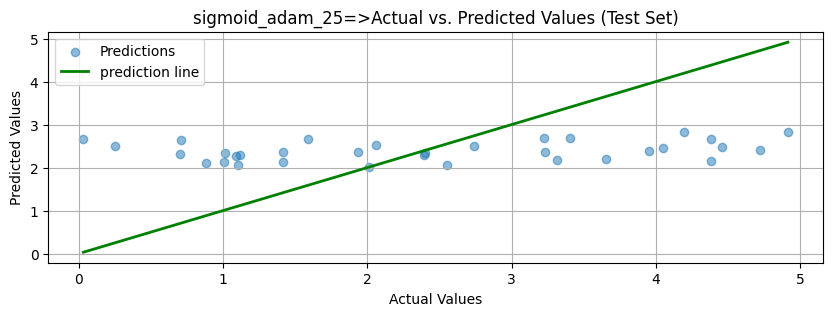

Model: sigmoid_adam_50, Test MSE: 1.901001214981079
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 240ms/step


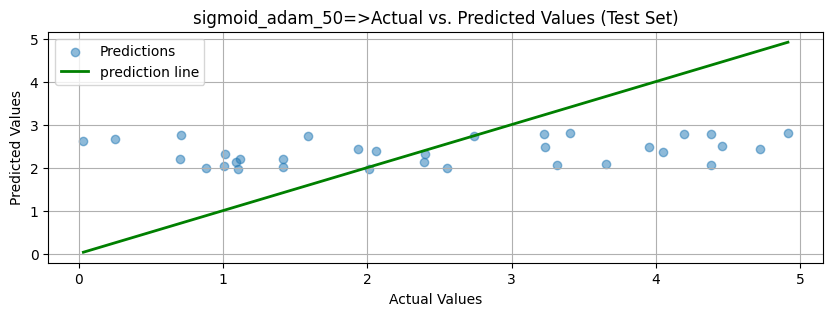

Model: sigmoid_adam_100, Test MSE: 1.8594034910202026
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


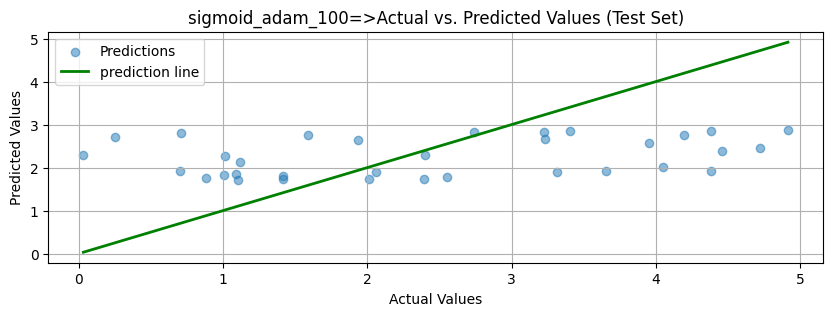

Model: sigmoid_adam_500, Test MSE: 1.792796015739441
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step


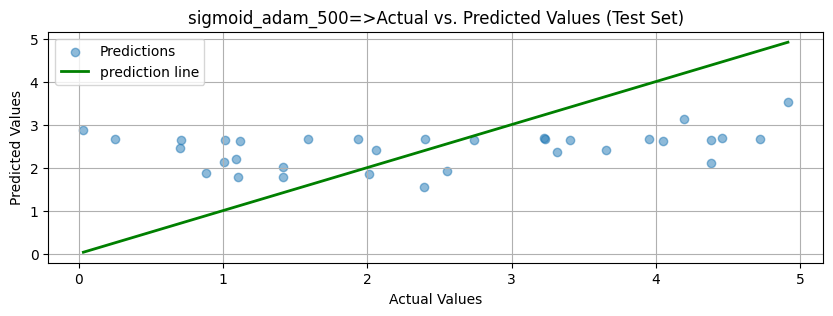

Model: sigmoid_sgd_25, Test MSE: 2.0555672645568848
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step


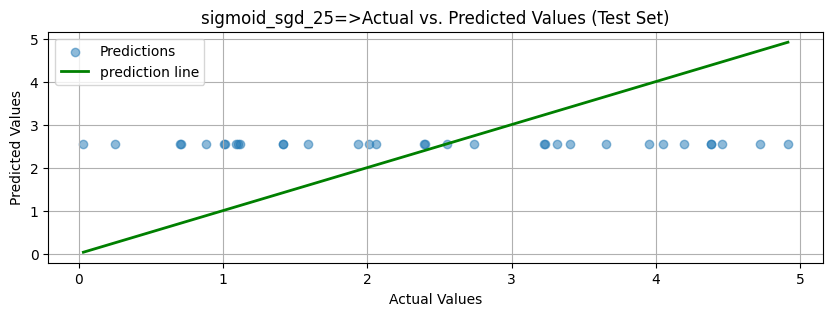

Model: sigmoid_sgd_50, Test MSE: 2.0493431091308594
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 252ms/step


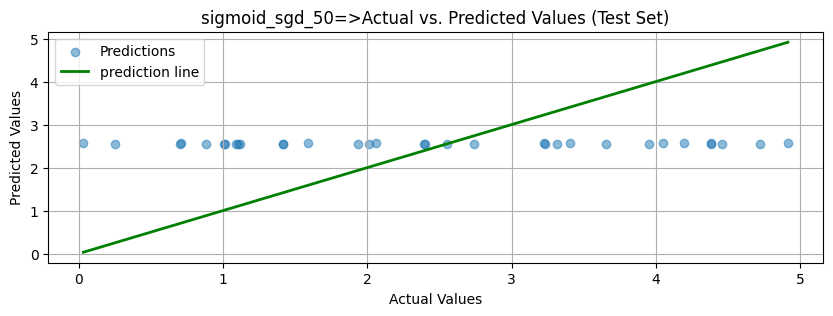

Model: sigmoid_sgd_100, Test MSE: 2.0408244132995605
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


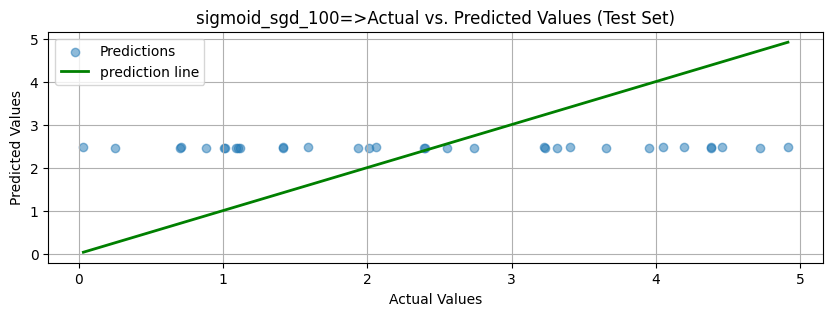

Model: sigmoid_sgd_500, Test MSE: 1.9428356885910034
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 253ms/step


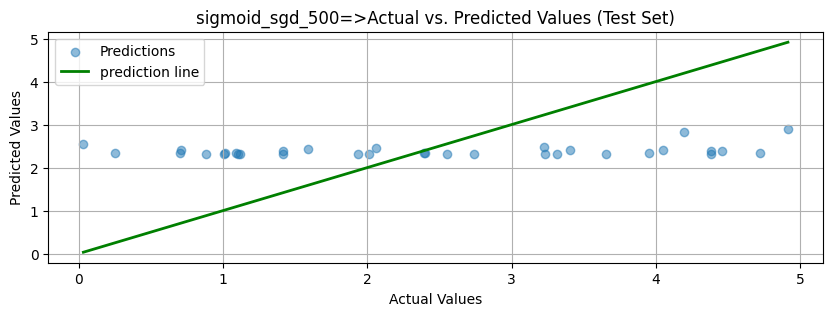

Model: sigmoid_rmsprop_25, Test MSE: 2.100795030593872
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step


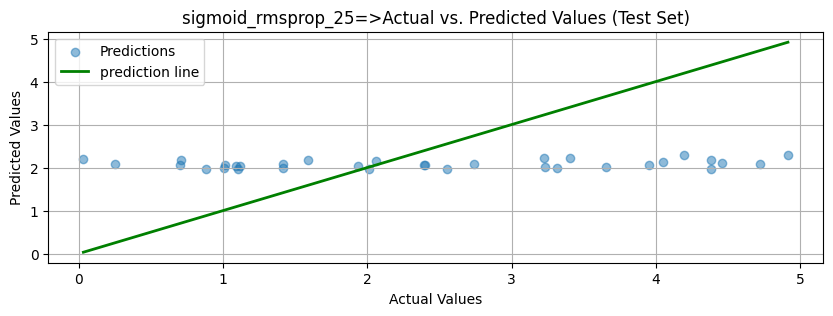

Model: sigmoid_rmsprop_50, Test MSE: 1.9082629680633545
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step


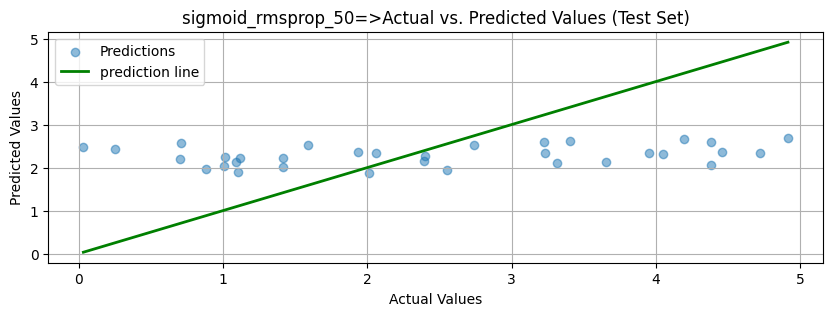

Model: sigmoid_rmsprop_100, Test MSE: 1.833472728729248
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 239ms/step


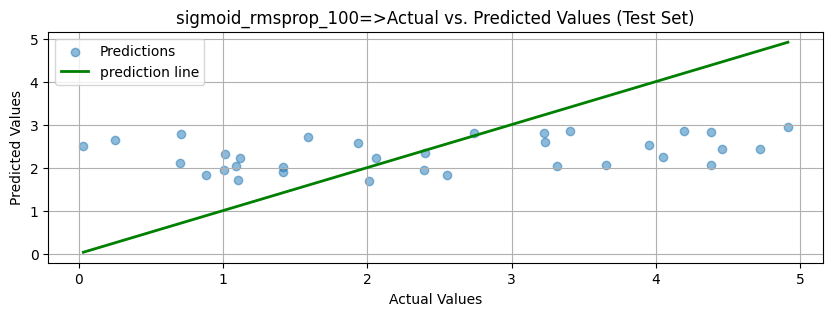

Model: sigmoid_rmsprop_500, Test MSE: 1.8354425430297852
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


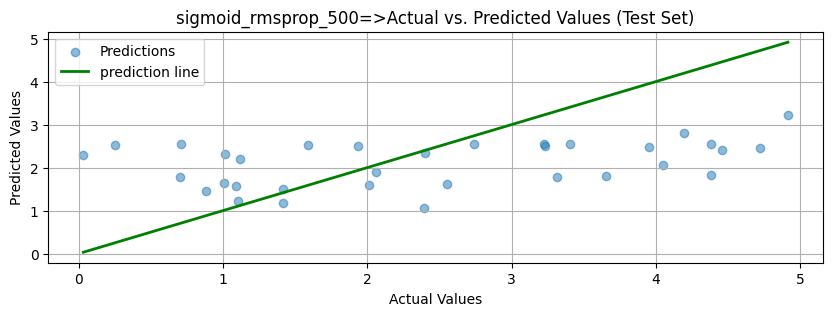

In [7]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")